# From images to flow: a patient-specific CFD workflow

What information is still missing after we have a picture of a heart chamber?

Fall 2023.


# Predict before running
The image is synthetic and the grid is only a sketch. Predict which threshold includes more pixels and which prescribed flow removes tracer faster. No calculus or code writing is required.

In [1]:
from demo import run, remaining_fraction, synthetic_image, segment
report = run()
print(report)

{'scope': 'well-mixed compartment surrogate, not resolved CFD', 'volume_ml': 100.0, 'fraction_at2s_Q25_50_100': [0.6065306597126334, 0.36787944117144233, 0.1353352832366127], 'time_constant_s_Q25_50_100': [4.0, 2.0, 1.0], 'mask_pixel_counts_at_thresholds04_05_06': [1699, 1641, 1563], 'checks': {'initial_fraction_one': True, 'no_flow_no_washout': True, 'ratio_invariance': True, 'threshold_masks_nested': True, 'invalid_inputs_rejected': 4}}


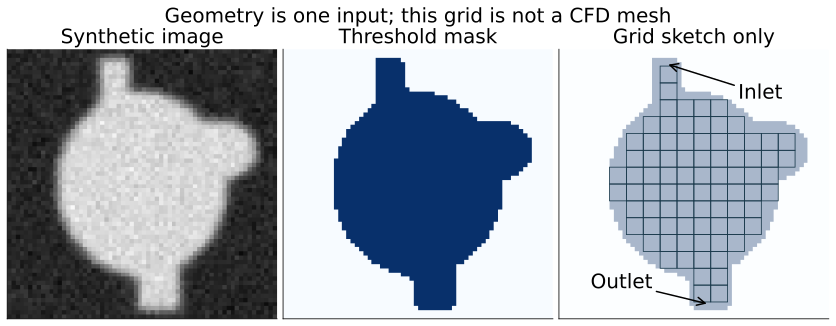

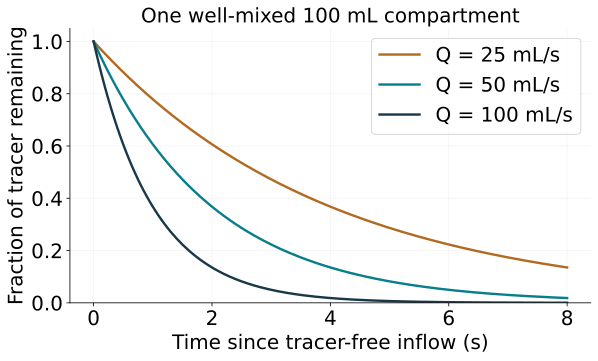

In [2]:
from IPython.display import SVG, display
display(SVG(filename="image-pipeline.svg"))
display(SVG(filename="washout.svg"))

## Interpret
Locate the pocket and two openings. List one geometric check, one boundary input and one independent validation observation. Explain why the concentration curve cannot reveal a spatial pocket.

In [3]:
chosen_flow = 50.0  # mL/s; change this one nonnegative number.
chosen_volume = 100.0  # mL
print("Remaining fraction at 2 s:", remaining_fraction(2.0, chosen_flow, chosen_volume))
print("Zero-flow check:", remaining_fraction(2.0, 0.0, chosen_volume))

Remaining fraction at 2 s: 0.36787944117144233
Zero-flow check: 1.0


## Modify and explain
Predict the result if flow doubles. Then restore flow and double both flow and volume. Explain the difference using the ratio, and write one supported claim with its mixing assumption.